In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [60]:
df = pd.read_csv("Lab 2 KNN.csv")

In [61]:
print("Dataset Preview")
print(df.head())

Dataset Preview
   Age  Salary  Experience_Years   Education City_Tier  Credit_Score  \
0   58   68354                28  HighSchool     Tier2           699   
1   48   22557                12  HighSchool     Tier1           522   
2   34   58360                11  HighSchool     Tier2           802   
3   27  102018                13         PhD     Tier2           845   
4   40   22200                 1  HighSchool     Tier3           801   

   Purchased  
0          1  
1          0  
2          1  
3          1  
4          1  


In [62]:
df.describe(include = 'all')

,Age,Salary,Experience_Years,Education,City_Tier,Credit_Score,Purchased
count,250.000000,250.000000,250.000000,250,250,250.000000,250.000000
unique,NaN,NaN,NaN,4,3,NaN,NaN
top,NaN,NaN,NaN,HighSchool,Tier3,NaN,NaN
freq,NaN,NaN,NaN,74,87,NaN,NaN
mean,39.716000,71833.556000,15.296000,NaN,NaN,678.516000,0.792000
std,12.058565,29456.483635,8.569605,NaN,NaN,99.731737,0.406691
min,20.000000,20301.000000,0.000000,NaN,NaN,500.000000,0.000000
25%,28.000000,46900.250000,8.000000,NaN,NaN,597.000000,1.000000
50%,41.000000,73114.000000,16.000000,NaN,NaN,676.500000,1.000000
75%,51.000000,97236.000000,23.000000,NaN,NaN,766.750000,1.000000


In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               250 non-null    int64 
 1   Salary            250 non-null    int64 
 2   Experience_Years  250 non-null    int64 
 3   Education         250 non-null    object
 4   City_Tier         250 non-null    object
 5   Credit_Score      250 non-null    int64 
 6   Purchased         250 non-null    int64 
dtypes: int64(5), object(2)
memory usage: 13.8+ KB


In [64]:
print(df.columns)
print(df.shape)
print(df.dtypes)

Index(['Age', 'Salary', 'Experience_Years', 'Education', 'City_Tier',
       'Credit_Score', 'Purchased'],
      dtype='object')
(250, 7)
Age                  int64
Salary               int64
Experience_Years     int64
Education           object
City_Tier           object
Credit_Score         int64
Purchased            int64
dtype: object


In [65]:
print(df.isnull().sum())

Age                 0
Salary              0
Experience_Years    0
Education           0
City_Tier           0
Credit_Score        0
Purchased           0
dtype: int64


In [66]:
df.replace('?', np.nan, inplace = True)

In [67]:
categorical_features = df.select_dtypes(include=['object']).columns
numerical_features = df.select_dtypes(include=['int64']).columns

In [68]:
print(categorical_features)
print(numerical_features)

Index(['Education', 'City_Tier'], dtype='object')
Index(['Age', 'Salary', 'Experience_Years', 'Credit_Score', 'Purchased'], dtype='object')


In [69]:
for col in categorical_features:
    df[col] = df[col].fillna(df[col].mode()[0])
for col in numerical_features:
    df[col] = df[col].fillna(df[col].median())

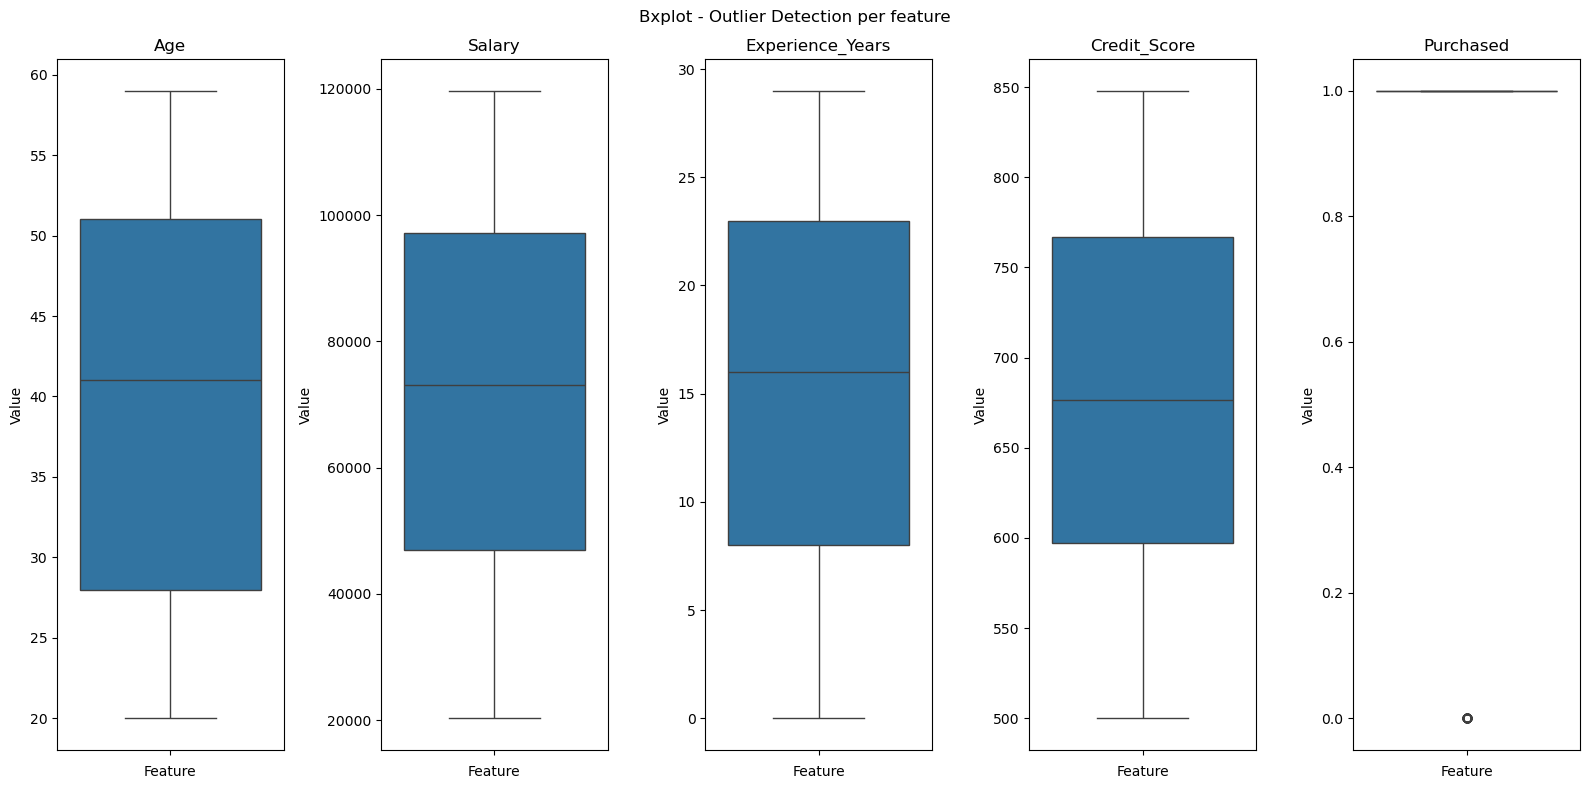

In [70]:
fig, axes = plt.subplots(1, len(numerical_features), figsize=(16,8))
for i, col in enumerate(numerical_features):
    sns.boxplot(y=df[col], ax = axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("Feature")
    axes[i].set_ylabel("Value")

plt.suptitle("Bxplot - Outlier Detection per feature")
plt.tight_layout()
plt.show()

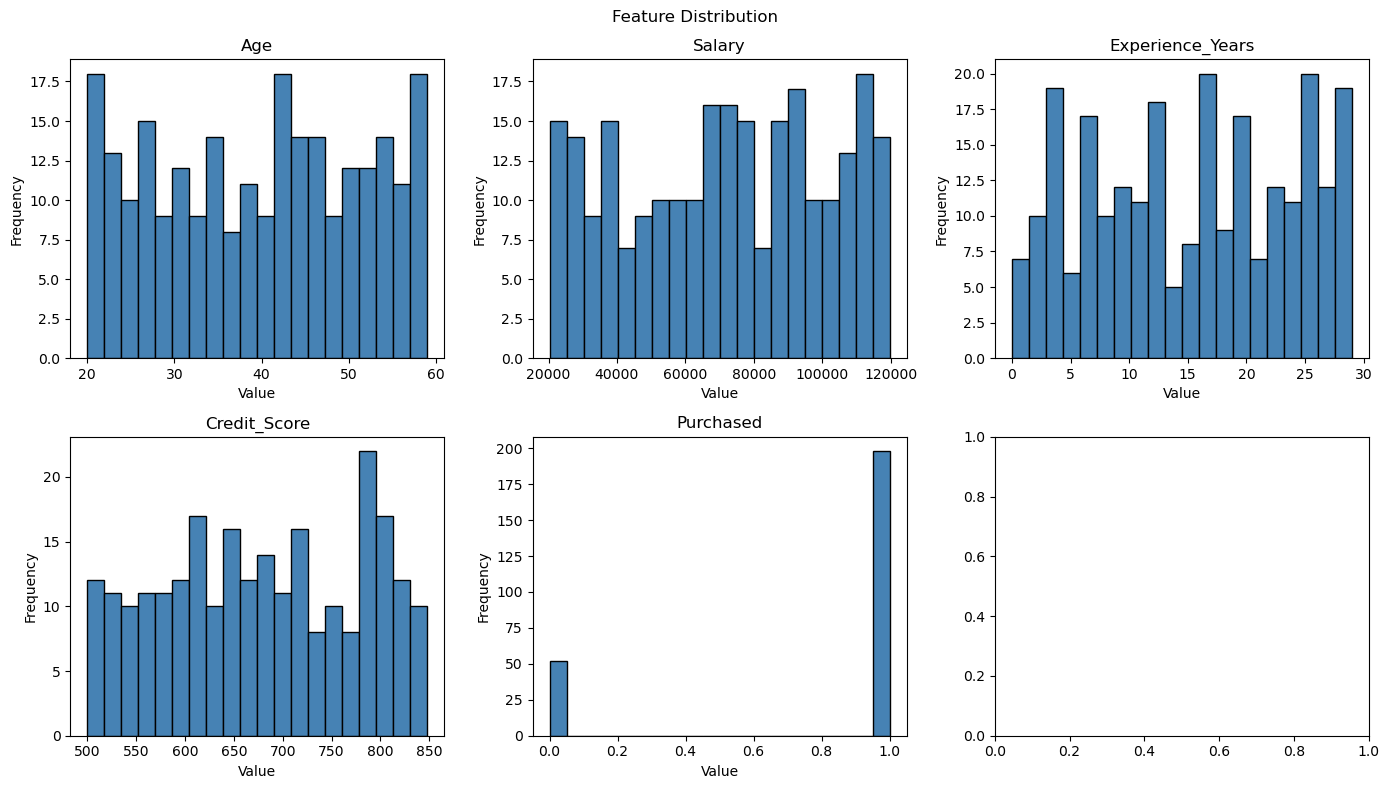

In [71]:
fig, axes = plt.subplots(2,3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    axes[i].hist(df[col], bins = 20, color = 'steelblue', edgecolor = 'black')
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

plt.suptitle("Feature Distribution")
plt.tight_layout()
plt.show()

In [72]:
def purchase(purch):
    if purch == 0:
        return "No"
    elif purch == 1:
        return "Yes"

df['Purchase'] = df['Purchased'].apply(purchase)

In [73]:
print(df.info(),"\n\n")
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               250 non-null    int64 
 1   Salary            250 non-null    int64 
 2   Experience_Years  250 non-null    int64 
 3   Education         250 non-null    object
 4   City_Tier         250 non-null    object
 5   Credit_Score      250 non-null    int64 
 6   Purchased         250 non-null    int64 
 7   Purchase          250 non-null    object
dtypes: int64(5), object(3)
memory usage: 15.8+ KB
None 


   Age  Salary  Experience_Years   Education City_Tier  Credit_Score  \
0   58   68354                28  HighSchool     Tier2           699   
1   48   22557                12  HighSchool     Tier1           522   
2   34   58360                11  HighSchool     Tier2           802   
3   27  102018                13         PhD     Tier2           845   
4   40   22200   

In [74]:
df = df.drop('Purchased', axis=1)
print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               250 non-null    int64 
 1   Salary            250 non-null    int64 
 2   Experience_Years  250 non-null    int64 
 3   Education         250 non-null    object
 4   City_Tier         250 non-null    object
 5   Credit_Score      250 non-null    int64 
 6   Purchase          250 non-null    object
dtypes: int64(4), object(3)
memory usage: 13.8+ KB
None
   Age  Salary  Experience_Years   Education City_Tier  Credit_Score Purchase
0   58   68354                28  HighSchool     Tier2           699      Yes
1   48   22557                12  HighSchool     Tier1           522       No
2   34   58360                11  HighSchool     Tier2           802      Yes
3   27  102018                13         PhD     Tier2           845      Yes
4   40   22200                 1  Hi

In [75]:
x = df.drop('Purchase', axis=1)
y = df['Purchase']

categorical_features = x.select_dtypes(include=['object']).columns
numerical_features = x.select_dtypes(include=['int64']).columns

# print(categorical_features)
# print(numerical_features)

x = pd.get_dummies(x, columns=categorical_features)
# print(x)

In [76]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state=42)
scaler = RobustScaler()
sample = x_train.copy()
x_train[numerical_features] = scaler.fit_transform(x_train[numerical_features])
x_test[numerical_features] = scaler.transform(x_test[numerical_features])

In [77]:
print("Before Scaling")
print(sample[numerical_features].describe())

print("After Scaling")
print(x_train[numerical_features].describe())

Before Scaling
              Age         Salary  Experience_Years  Credit_Score
count  175.000000     175.000000        175.000000    175.000000
mean    40.268571   73315.388571         15.045714    671.068571
std     12.068858   29857.232161          8.575437    103.494938
min     20.000000   21150.000000          0.000000    500.000000
25%     29.000000   49358.000000          7.000000    583.500000
50%     43.000000   74045.000000         15.000000    667.000000
75%     51.000000  100436.500000         23.000000    763.000000
max     59.000000  119713.000000         29.000000    846.000000
After Scaling
              Age      Salary  Experience_Years  Credit_Score
count  175.000000  175.000000        175.000000    175.000000
mean    -0.124156   -0.014284          0.002857      0.022666
std      0.548584    0.584536          0.535965      0.576573
min     -1.045455   -1.035563         -0.937500     -0.930362
25%     -0.636364   -0.483315         -0.500000     -0.465181
50%      0.000

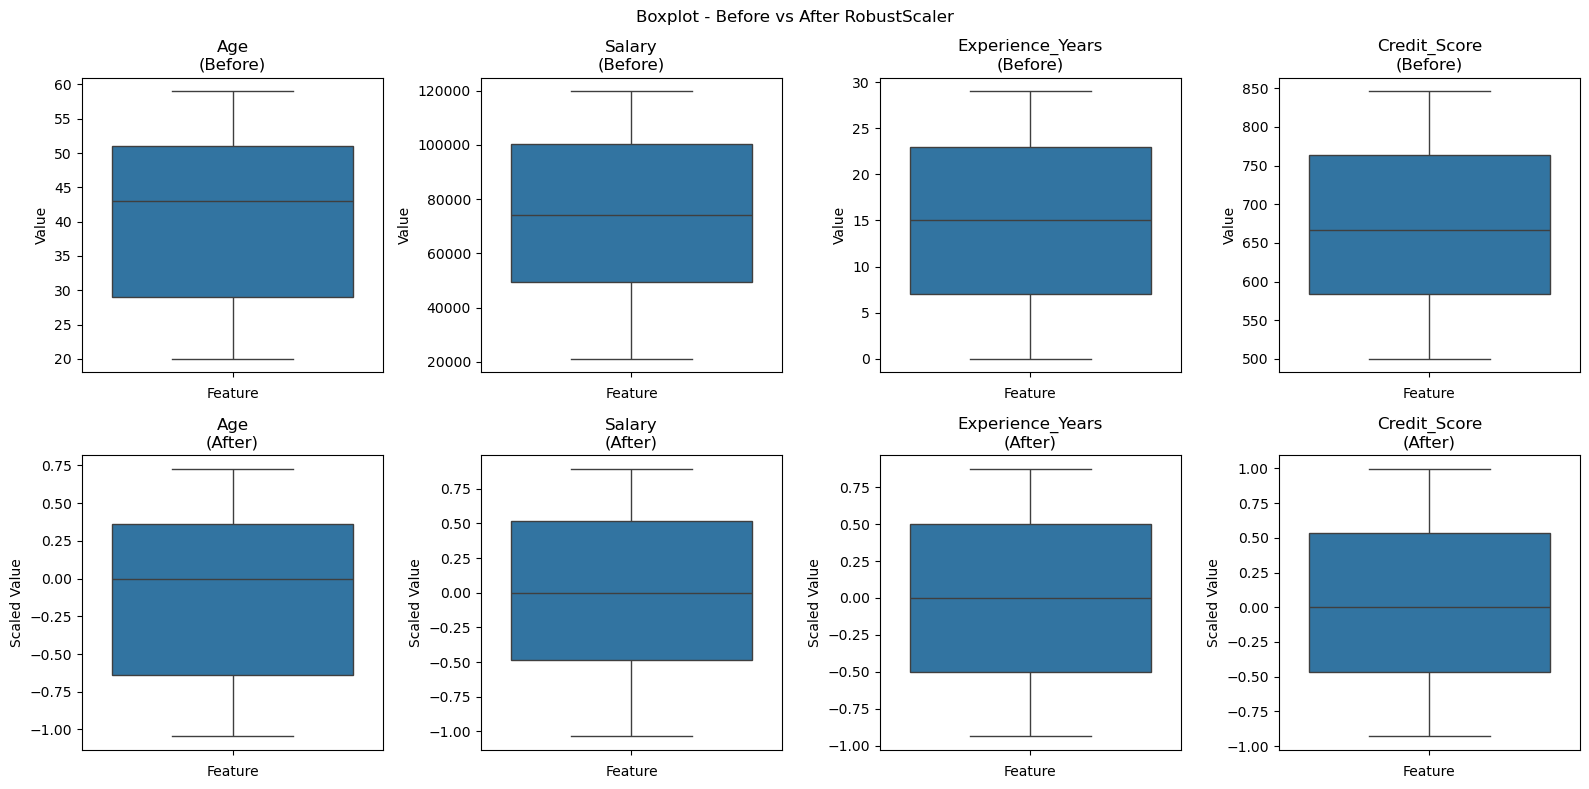

In [84]:
# Visual check - Boxplots before vs after (run BEFORE feature engineering for before plots)
fig, axes = plt.subplots(2, len(numerical_features), figsize=(16, 8))

# --- Top row: BEFORE scaling (use df, original data) ---
for i, col in enumerate(numerical_features):
    sns.boxplot(y=sample[col], ax=axes[0, i])
    axes[0, i].set_title(f"{col}\n(Before)")
    axes[0, i].set_ylabel("Value")
    axes[0, i].set_xlabel("Feature")

# --- Bottom row: AFTER scaling ---
for i, col in enumerate(numerical_features):
    sns.boxplot(y=x_train[col], ax=axes[1, i])
    axes[1, i].set_title(f"{col}\n(After)")
    axes[1, i].set_ylabel("Scaled Value")
    axes[1, i].set_xlabel("Feature")

plt.suptitle("Boxplot - Before vs After RobustScaler")
plt.tight_layout()
plt.show()

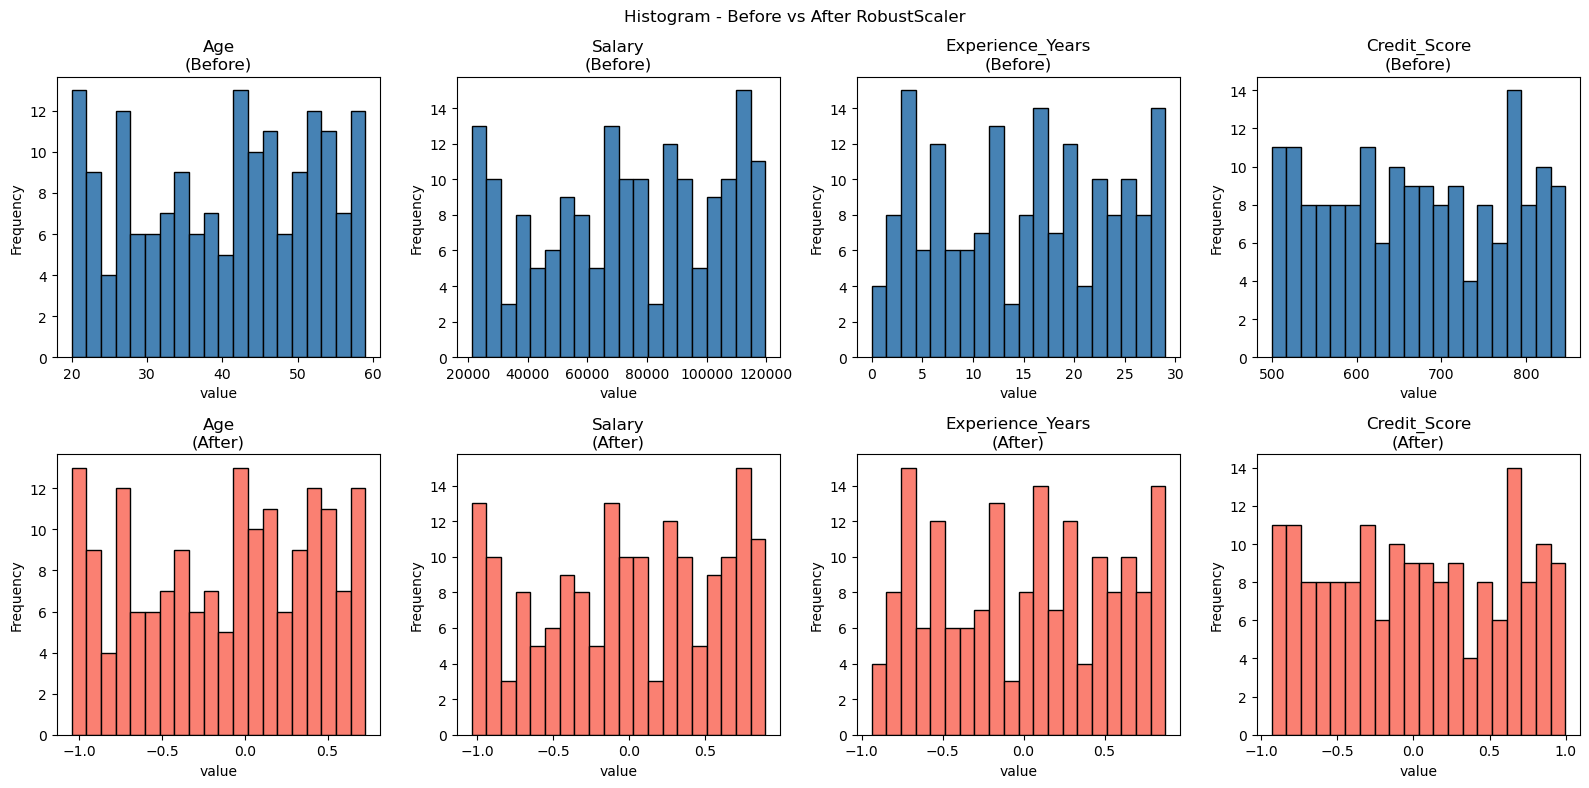

In [85]:
fig, axes = plt.subplots(2, len(numerical_features), figsize=(16,8))

for i, col in enumerate(numerical_features):
    axes[0,i].hist(sample[col], bins=20, color='steelblue', edgecolor='black')
    axes[0,i].set_title(f"{col}\n(Before)")
    axes[0,i].set_xlabel("value")
    axes[0,i].set_ylabel("Frequency")

for i, col in enumerate(numerical_features):
    axes[1,i].hist(x_train[col], bins=20, color='salmon', edgecolor='black')
    axes[1,i].set_title(f"{col}\n(After)")
    axes[1,i].set_xlabel("value")
    axes[1,i].set_ylabel("Frequency")

plt.suptitle("Histogram - Before vs After RobustScaler")
plt.tight_layout()
plt.show()

In [80]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(x_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [81]:
y_pred = model.predict(x_test)

In [45]:
accuracy = accuracy_score(y_test, y_pred)

mse = mean_squared_error(
    pd.factorize(y_test)[0],
    pd.factorize(y_pred)[0]
)

print("\nModel Accuracy: ", accuracy)
print("\nMean Squarred Error: ", mse)

print("\nConfusion Matrix: \n")
print(confusion_matrix(y_test, y_pred))


Model Accuracy:  0.88

Mean Squarred Error:  0.12

Confusion Matrix: 

[[ 9  6]
 [ 3 57]]


In [82]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Classification Report:

              precision    recall  f1-score   support

          No       0.75      0.60      0.67        15
         Yes       0.90      0.95      0.93        60

    accuracy                           0.88        75
   macro avg       0.83      0.77      0.80        75
weighted avg       0.87      0.88      0.87        75



In [83]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print("\nPrediction results:\n")
print(results)


Prediction results:

    Actual Predicted
142    Yes       Yes
6      Yes       Yes
97      No        No
60      No       Yes
112    Yes       Yes
..     ...       ...
73     Yes       Yes
158    Yes       Yes
115    Yes       Yes
75      No       Yes
237    Yes       Yes

[75 rows x 2 columns]
